In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

# Путь к подготовленному датасету
data_path = Path("../data/processed/SeoulBikeData_clean.csv")

# Если Jupyter запущен из корня проекта
if not data_path.exists():
    data_path = Path("data/processed/SeoulBikeData_clean.csv")

# Загружаем данные
df = pd.read_csv(data_path, parse_dates=["Date"])

print("Размер:", df.shape)
print("Тип даты:", df["Date"].dtype)

display(df.head())

Размер: (8760, 14)
Тип даты: datetime64[us]


,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


## Подготовка признаков и разделение данных

Цель: выделить X и y, затем разделить данные по времени
на обучающую (80%) и тестовую (20%) части.

Целевая переменная: Rented Bike Count.

In [3]:

# 1. Упорядочиваем данные по дате и часу
df = df.sort_values(["Date", "Hour"]).reset_index(drop=True)

# 2. Создаём два дополнительных признака из даты
df["month"] = df["Date"].dt.month
df["day_of_week"] = df["Date"].dt.day_of_week

# 3. y — то, что нужно предсказать
y = df["Rented Bike Count"]

# 4. X — признаки, по которым будем предсказывать
X = df.drop(columns=["Rented Bike Count", "Date"])

# Проверяем, что правильный ответ не попал в X
assert "Rented Bike Count" not in X.columns

# 5. Граница между обучением и проверкой (80/20)
split = int(len(df) * 0.8)

# 6. Разделяем признаки и правильные ответы
X_train = X.iloc[:split].copy()
X_test = X.iloc[split:].copy()

y_train = y.iloc[:split].copy()
y_test = y.iloc[split:].copy()

# 7. Проверяем результат
print("Признаки X:", X.shape)
print("Цель y:", y.shape)
print()
print("TRAIN:", X_train.shape, y_train.shape)
print("TEST:", X_test.shape, y_test.shape)
print()
print("Последняя дата TRAIN:", df.iloc[split - 1]["Date"].date())
print("Первая дата TEST:", df.iloc[split]["Date"].date())
print()
print("Список признаков:")
print(X.columns.tolist())


Признаки X: (8760, 14)
Цель y: (8760,)

TRAIN: (7008, 14) (7008,)
TEST: (1752, 14) (1752,)

Последняя дата TRAIN: 2018-09-18
Первая дата TEST: 2018-09-19

Список признаков:
['Hour', 'Temperature(°C)', 'Humidity(%)', 'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(°C)', 'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons', 'Holiday', 'Functioning Day', 'month', 'day_of_week']


In [4]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Текстовые признаки
categorical_features = [
    "Seasons",
    "Holiday",
    "Functioning Day"
]

# Все остальные признаки — числовые
numeric_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

# Правила преобразования признаков
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Числовых признаков:", len(numeric_features))
print("Категориальных признаков:", len(categorical_features))
print("Preprocessing настроен!")

Числовых признаков: 11
Категориальных признаков: 3
Preprocessing настроен!


In [5]:

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Объединяем преобразование признаков и модель
linear_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", LinearRegression())
])

print("Pipeline создан!")
print(linear_pipeline)


Pipeline создан!
Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Hour', 'Temperature(°C)',
                                                   'Humidity(%)',
                                                   'Wind speed (m/s)',
                                                   'Visibility (10m)',
                                                   'Dew point temperature(°C)',
                                                   'Solar Radiation (MJ/m2)',
                                                   'Rainfall(mm)',
                                                   'Snowfall (cm)', 'month',
                                                   'day_of_week']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Seasons', 'Holiday'

## Обучение и оценка моделей

Сравниваем простой DummyRegressor и LinearRegression.
Обучение проводится на TRAIN, оценка — на TEST.
Метрики: MAE, RMSE, R².

In [6]:

from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

# 1. Простейшая контрольная модель
dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(X_train, y_train)

# 2. Обучаем Linear Regression вместе с preprocessing
linear_pipeline.fit(X_train, y_train)

# 3. Получаем прогнозы на одинаковом TEST
dummy_pred = dummy_model.predict(X_test)
linear_pred = linear_pipeline.predict(X_test)

# 4. Функция расчёта метрик
def evaluate_model(name, y_true, y_pred):
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred)
    }

# 5. Сравниваем результаты
results = pd.DataFrame([
    evaluate_model("Dummy Baseline", y_test, dummy_pred),
    evaluate_model("Linear Regression", y_test, linear_pred)
])

display(results.round(3))


,Model,MAE,RMSE,R2
0,Dummy Baseline,500.999,616.819,-0.011
1,Linear Regression,310.877,409.072,0.555


## Визуализация результатов

Сравнение фактического и предсказанного спроса за первые 7 дней тестового периода.

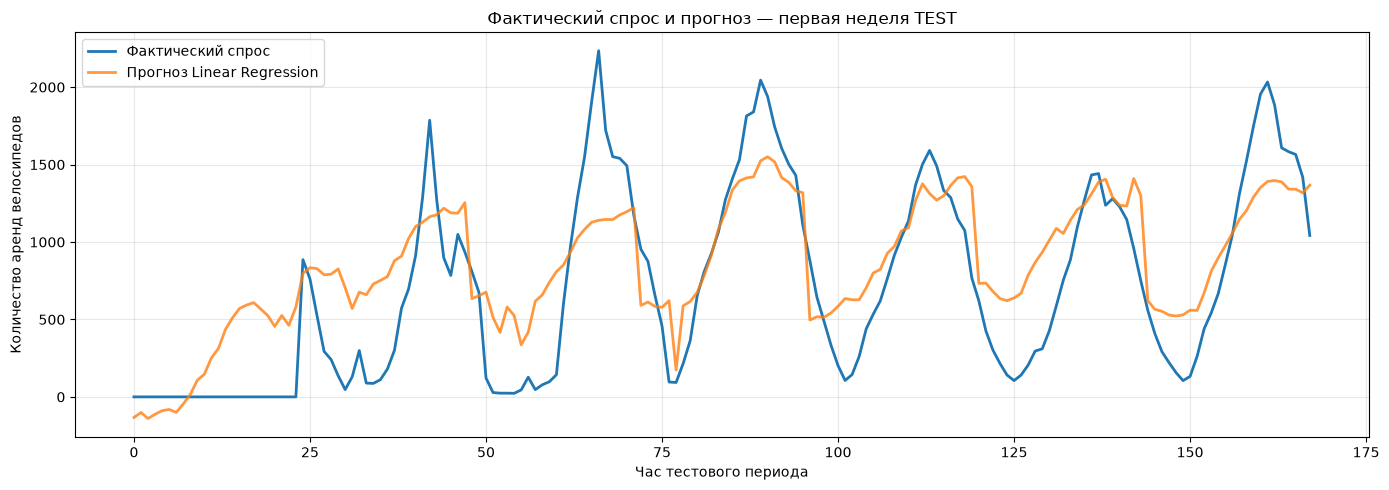

In [7]:

# Показываем первую неделю TEST: 7 дней по 24 часа
n = 7 * 24

plt.figure(figsize=(14, 5))

plt.plot(
    range(n),
    y_test.to_numpy()[:n],
    label="Фактический спрос",
    linewidth=2
)

plt.plot(
    range(n),
    linear_pred[:n],
    label="Прогноз Linear Regression",
    linewidth=2,
    alpha=0.8
)

plt.title("Фактический спрос и прогноз — первая неделя TEST")
plt.xlabel("Час тестового периода")
plt.ylabel("Количество аренд велосипедов")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
